# POKEMON

### Analitika kitabxanalarının yüklənməsi və Datasetin Gətirilməsi

In [4]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

df=pd.read_excel(r"C:\Users\sabin\Downloads\Pokemon.xlsx")
df

,#,name,type1,type2,base_total,hp,attack,defense,sp_attack,sp_defense,speed,height_m,weight_kg,is_legendary,generation,capture_rate,base_happiness,percentage_male
0,1,Bulbasaur,grass,poison,318,45,49,49,65,65,45,0.7,6.9,0,1,45,70,88.1
1,2,Ivysaur,grass,poison,405,60,62,63,80,80,60,1.0,13.0,0,1,45,70,88.1
2,3,Venusaur,grass,poison,625,80,100,123,122,120,80,2.0,100.0,0,1,45,70,88.1
3,4,Charmander,fire,NaN,309,39,52,43,60,50,65,0.6,8.5,0,1,45,70,88.1
4,5,Charmeleon,fire,NaN,405,58,64,58,80,65,80,1.1,19.0,0,1,45,70,88.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,796,Celesteela,steel,flying,570,97,101,103,107,101,61,9.2,999.9,1,7,25,0,NaN
796,797,Kartana,grass,steel,570,59,181,131,59,31,109,0.3,0.1,1,7,255,0,NaN
797,798,Guzzlord,dark,dragon,570,223,101,53,97,53,43,5.5,888.0,1,7,15,0,NaN
798,799,Necrozma,psychic,NaN,600,97,107,101,127,89,79,2.4,230.0,1,7,3,0,NaN


#### Datasetdə ən çox yayılmış Pokemon növü hansıdır? Bu tip nə qədər Pokemon var?

en cox yayilmis tip: type1
water    114
Name: count, dtype: int64


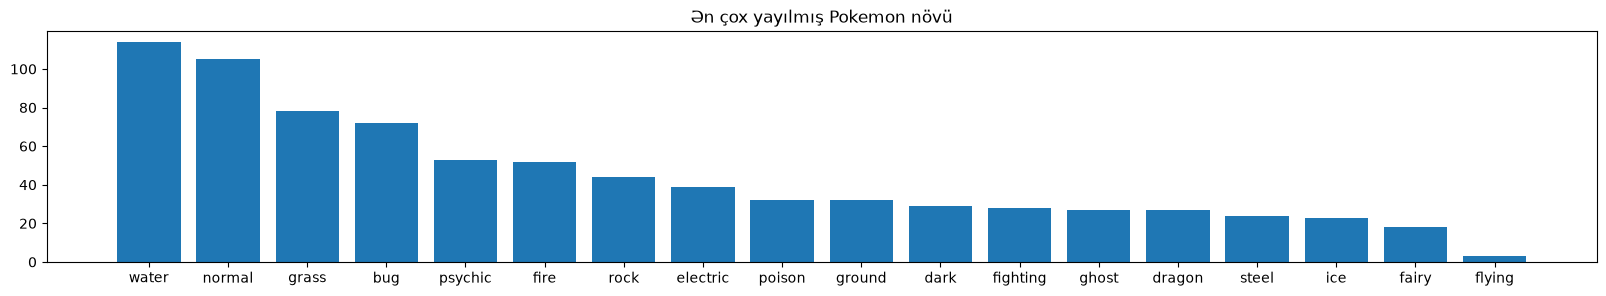

In [9]:
en_cox_yayilmis_tip=df['type1'].value_counts().head(1)
print('en cox yayilmis tip:',en_cox_yayilmis_tip)

plt.figure(figsize=(20,3))
plt.bar(df['type1'].value_counts().index,df['type1'].value_counts())
plt.title('Ən çox yayılmış Pokemon növü')
plt.show()

#### Digər növləri ilə müqayisədə həddindən artıq yüksək və ya aşağı statistikaya malik hər hansı Pokemon varmı?

In [11]:
df.groupby('type1')['base_total'].mean().sort_values()
#bug asagi;psychic,steel,dragon ise nisbeten yuksek statistikaya malikdir.

type1
bug         380.430556
poison      399.562500
normal      401.295238
grass       412.576923
fighting    414.821429
ground      426.093750
water       426.789474
fairy       427.166667
ice         433.608696
ghost       434.703704
electric    436.153846
rock        446.068182
dark        449.758621
fire        450.634615
flying      453.333333
psychic     461.264151
steel       491.583333
dragon      522.777778
Name: base_total, dtype: float64

#### Pokemonun capture rate ilə onun base total arasında əlaqə varmı? Bəs onun nadirliyi (legendary və ya deyil)?

In [13]:
print('Capture rate ile total_base arasinda elaqenin gucu', df['capture_rate'].corr(df['base_total']))
# Aralarında mənfi əlaqə mövcuddur. Base_total artdıqca capture_rate azalmağa meyillidir.Yuksek guce malik pokemonlari tutmaq nisbeten cetindir.

print('islegendary ile total_base arasinda elaqenin gucu',df['is_legendary'].corr(df['base_total']))
#Burda ise orta güclü müsbət əlaqə var. Legendary olan Pokémonların base_total göstəricisi daha yüksək olmağa meyillidir.

Capture rate ile total_base arasinda elaqenin gucu -0.7121201962428769
islegendary ile total_base arasinda elaqenin gucu 0.4858112178201077


#### Hansı Pokemon ən yüksək hücum statistikasına malikdir?

In [14]:
df.nlargest(1, 'sp_attack')[['name', 'attack','sp_attack']]

,name,attack,sp_attack
149,Mewtwo,150,194


#### Base total ilə HP, Attack, Defense, Special Attack, Special Defense və Speed kimi digər atributların hər biri arasında correlation nədir?

In [15]:
print('base total ve hp arasında əlaqə:',df['base_total'].corr(df['hp']))
print('base total ve attack arasında əlaqə:',df['base_total'].corr(df['attack']))
print('base total ve defense arasında əlaqə:',df['base_total'].corr(df['defense']))
print('base total ve sp_attack arasında əlaqə:',df['base_total'].corr(df['sp_attack']))
print('base total ve sp_defense arasında əlaqə:',df['base_total'].corr(df['sp_defense']))
print('base total ve speed arasında əlaqə:',df['base_total'].corr(df['speed']))

base total ve hp arasında əlaqə: 0.6210619115159873
base total ve attack arasında əlaqə: 0.7299978264684948
base total ve defense arasında əlaqə: 0.6301512169063509
base total ve sp_attack arasında əlaqə: 0.7409856986308718
base total ve sp_defense arasında əlaqə: 0.7179583541478484
base total ve speed arasında əlaqə: 0.5475754890793932


#### Əfsanəvi və əfsanəvi olmayan Pokemonun ortalama hücum  arasında əhəmiyyətli fərq varmı?

In [16]:
print('attack:',df.groupby('is_legendary')['attack'].mean())
print('sp_attack:',df.groupby('is_legendary')['sp_attack'].mean())

#Bəli. Legendary pokemonlar ortalama texminen %50-%70 daha yuksek hucum gucune malikdir.

attack: is_legendary
0     74.806849
1    109.357143
Name: attack, dtype: float64
sp_attack: is_legendary
0     67.195890
1    113.757143
Name: sp_attack, dtype: float64


#### Hansı tip 1 və tip 2 kombinasiyaları Pokemonlar arasında ən çox yayılmışdır?

In [17]:
df[['type1','type2']].value_counts().head(1)

type1   type2 
normal  flying    26
Name: count, dtype: int64

#### Pokemonun çəkisi və boyu arasında korrelyasiya varmı?

In [18]:
print('Pokemonun çəkisi və boyu arasında korrelyasiya:',df['weight_kg'].corr(df['height_m']))

Pokemonun çəkisi və boyu arasında korrelyasiya: 0.6266230704400672


#### Hansı nəsil (generation) ən yüksək ortalama sürətə malikdir?

In [19]:
df.groupby('generation')['speed'].mean().sort_values(ascending=False).head(1)

generation
1    70.152318
Name: speed, dtype: float64

#### Base total paylanması əfsanəvi və əfsanəvi olmayan Pokemon arasında necə dəyişir?

In [20]:
df.groupby('is_legendary')['base_total'].describe()

,count,mean,std,min,25%,50%,75%,max
is_legendary,,,,,,,,
0,730.0,410.358904,106.120037,180.0,316.5,418.0,493.0,700.0
1,70.0,615.257143,82.634990,200.0,580.0,600.0,680.0,780.0


#### Müxtəlif Pokemon tipləri arasında Defense paylanmasında əhəmiyyətli fərq varmı?

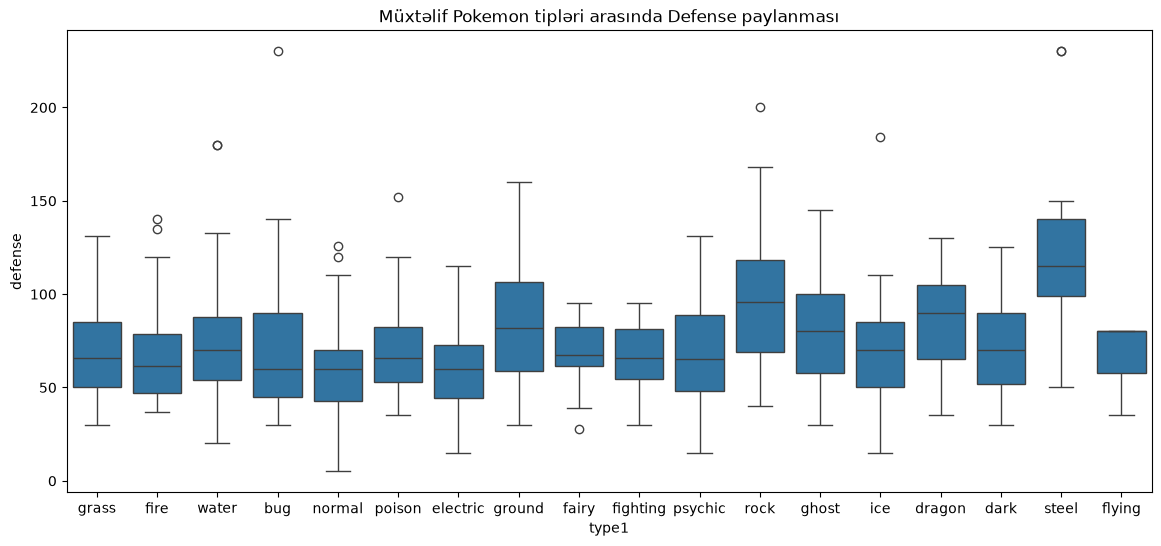

In [22]:
plt.figure(figsize=(14,6))
sns.boxplot(x='type1',y='defense',data=df)
plt.title('Müxtəlif Pokemon tipləri arasında Defense paylanması')
plt.show()

# ground, rock ve steel tipinde defense paylanmasinda ehemiyyetli ferq var ve digerlerinden yuksekdir.

#### Pokemonun adını input kimi qəbul edən və onun statistikalarının olduğu lüğətini qaytaran funksiya yazın.

In [23]:
def get_pokemon(pokemon_name):
    pokemon = df[df['name'] == pokemon_name]

    if pokemon['name'].count() == 0:
        return 'Pokemon movcud deil.'

    return pokemon.iloc[0]

get_pokemon('Kartana')

#                      797
name               Kartana
type1                grass
type2                steel
base_total             570
hp                      59
attack                 181
defense                131
sp_attack               59
sp_defense              31
speed                  109
height_m               0.3
weight_kg              0.1
is_legendary             1
generation               7
capture_rate           255
base_happiness           0
percentage_male        NaN
Name: 796, dtype: object

#### Percentage_male sütununda boş dəyərləri öz tipinin ortalaması ilə doldurun

In [24]:
df['percentage_male']=df['percentage_male'].fillna(df.groupby('type1')['percentage_male'].transform('mean'))
df

,#,name,type1,type2,base_total,hp,attack,defense,sp_attack,sp_defense,speed,height_m,weight_kg,is_legendary,generation,capture_rate,base_happiness,percentage_male
0,1,Bulbasaur,grass,poison,318,45,49,49,65,65,45,0.7,6.9,0,1,45,70,88.100000
1,2,Ivysaur,grass,poison,405,60,62,63,80,80,60,1.0,13.0,0,1,45,70,88.100000
2,3,Venusaur,grass,poison,625,80,100,123,122,120,80,2.0,100.0,0,1,45,70,88.100000
3,4,Charmander,fire,NaN,309,39,52,43,60,50,65,0.6,8.5,0,1,45,70,88.100000
4,5,Charmeleon,fire,NaN,405,58,64,58,80,65,80,1.1,19.0,0,1,45,70,88.100000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,796,Celesteela,steel,flying,570,97,101,103,107,101,61,9.2,999.9,1,7,25,0,50.000000
796,797,Kartana,grass,steel,570,59,181,131,59,31,109,0.3,0.1,1,7,255,0,58.978378
797,798,Guzzlord,dark,dragon,570,223,101,53,97,53,43,5.5,888.0,1,7,15,0,50.550000
798,799,Necrozma,psychic,NaN,600,97,107,101,127,89,79,2.4,230.0,1,7,3,0,51.058333


#### Daha çox kişiyə yaxın olan pokemonlar daha güclüdür, yoxsa qadına yaxın olanlar?

In [25]:
def gender(faiz):
    if faiz>50:
        return 'Kişiyə yaxın '
    elif faiz<50:
        return 'Qadına yaxın '
    else:
        return 'Bərabər '
df['gender_group']=df['percentage_male'].apply(gender)
cins_muqasiyesi=df.groupby('gender_group')[['base_total','attack']].mean()
print(cins_muqasiyesi)
df

               base_total     attack
gender_group                        
Bərabər        410.180077  75.852490
Kişiyə yaxın   470.658654  86.307692
Qadına yaxın   437.414286  67.385714


,#,name,type1,type2,base_total,hp,attack,defense,sp_attack,sp_defense,speed,height_m,weight_kg,is_legendary,generation,capture_rate,base_happiness,percentage_male,gender_group
0,1,Bulbasaur,grass,poison,318,45,49,49,65,65,45,0.7,6.9,0,1,45,70,88.100000,Kişiyə yaxın
1,2,Ivysaur,grass,poison,405,60,62,63,80,80,60,1.0,13.0,0,1,45,70,88.100000,Kişiyə yaxın
2,3,Venusaur,grass,poison,625,80,100,123,122,120,80,2.0,100.0,0,1,45,70,88.100000,Kişiyə yaxın
3,4,Charmander,fire,NaN,309,39,52,43,60,50,65,0.6,8.5,0,1,45,70,88.100000,Kişiyə yaxın
4,5,Charmeleon,fire,NaN,405,58,64,58,80,65,80,1.1,19.0,0,1,45,70,88.100000,Kişiyə yaxın
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,796,Celesteela,steel,flying,570,97,101,103,107,101,61,9.2,999.9,1,7,25,0,50.000000,Bərabər
796,797,Kartana,grass,steel,570,59,181,131,59,31,109,0.3,0.1,1,7,255,0,58.978378,Kişiyə yaxın
797,798,Guzzlord,dark,dragon,570,223,101,53,97,53,43,5.5,888.0,1,7,15,0,50.550000,Kişiyə yaxın
798,799,Necrozma,psychic,NaN,600,97,107,101,127,89,79,2.4,230.0,1,7,3,0,51.058333,Kişiyə yaxın


#### Əfsanəvi və ya əfsanəvi olmayan pokemonların ortalama çəkiləri və boyları arasında önəmli bir fərq var?

In [26]:
round(df.groupby('is_legendary')[['height_m','weight_kg']].mean(),2)

,height_m,weight_kg
is_legendary,,
0,1.06,48.02
1,2.28,199.35


#### Hansı tip1 və tip2 kombinasiyası daha xoşbəxtdir?

In [27]:
happy = df.groupby(['type1', 'type2'])['base_happiness'].mean().reset_index().sort_values(by='base_happiness', ascending=False)

print("Ən xoşbəxt kombinasiya:",happy.head())

Ən xoşbəxt kombinasiya:        type1  type2  base_happiness
110  psychic  grass           100.0
65     grass  grass           100.0
49      fire  steel           100.0
50      fire  water           100.0
107  psychic   fire           100.0


#### Tiplər üzrə ortalama çəki və boyları tapın

In [28]:
print(df.groupby('type1')[['height_m','weight_kg']].mean())
print(df.groupby('type2')[['height_m','weight_kg']].mean())

          height_m   weight_kg
type1                         
bug       0.883333   33.083333
dark      1.296552   69.096552
dragon    1.937037  107.125926
electric  0.981579   37.944737
fairy     0.794444   23.555556
fighting  1.196429   58.675000
fire      1.168000   66.096000
flying    1.166667   52.000000
ghost     1.251852   69.570370
grass     0.938961   33.255844
ground    1.340741  150.044444
ice       1.208696  103.260870
normal    1.024752   46.158416
poison    1.160000   33.830000
psychic   1.063462   57.328846
rock      1.330000   94.270000
steel     1.875000  188.841667
water     1.283333   51.071930
          height_m   weight_kg
type2                         
bug       1.020000   35.740000
dark      1.270588   67.058824
dragon    2.388235  235.358824
electric  1.025000   57.612500
fairy     0.744828   16.665517
fighting  1.416000   85.460000
fire      1.108333   52.075000
flying    1.358511   50.948936
ghost     1.461538   65.015385
grass     1.055000   35.355000
ground  

### Mən oynamaq üçün ən ideal pokemonu seçmək istəsəm, hansını seçməliyəm? Bunun üçün özünüzə uyğun xüsusi bir analiz aparın və seçdiyiniz pokemonu əsaslandırın

In [29]:
a=pd.DataFrame(df.nlargest(10,'base_total')[['name','base_total']])
a

,name,base_total
149,Mewtwo,780
383,Rayquaza,780
381,Kyogre,770
382,Groudon,770
492,Arceus,720
717,Zygarde,708
247,Tyranitar,700
372,Salamence,700
375,Metagross,700
379,Latias,700


#### Apardığınız analizlərin nəticəsinə uyğun olaraq vizuallaşdırmalar aparın və bir dashboard qurun

C:\Users\sabin\AppData\Local\Temp\ipykernel_21528\2270119018.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='name', y='base_total', data=a, palette='Blues')


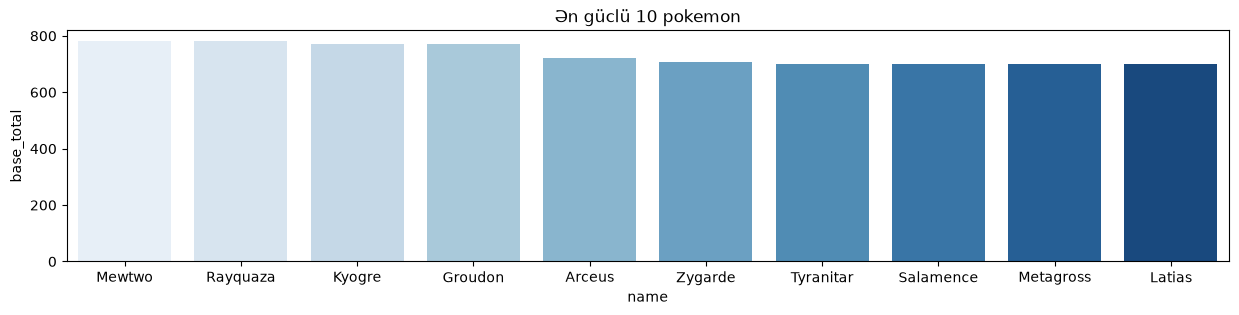

In [38]:
plt.figure(figsize=(15, 3))
sns.barplot(x='name', y='base_total', data=a, palette='Blues')
plt.title('Ən güclü 10 pokemon')
plt.show()